# Board Games!!!

The goal of this is to guess wether a game is complex or simple based on other variables. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_fscore_support


In [2]:
db = pd.read_csv('data/bgg_dataset.csv', sep=';', decimal=',')
db.head()

,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users,Mechanics,Domains
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,3.86,68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games"
1,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,2.84,65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games"
2,224517.0,Brass: Birmingham,2018.0,2,4,120,14,19217,8.66,3,3.91,28785.0,"Hand Management, Income, Loans, Market, Networ...",Strategy Games
3,167791.0,Terraforming Mars,2016.0,1,5,120,12,64864,8.43,4,3.24,87099.0,"Card Drafting, Drafting, End Game Bonuses, Han...",Strategy Games
4,233078.0,Twilight Imperium: Fourth Edition,2017.0,3,6,480,14,13468,8.70,5,4.22,16831.0,"Action Drafting, Area Majority / Influence, Ar...","Strategy Games, Thematic Games"


In [3]:
# 1. Inspect summary statistics and missing values
print(db.info())

# 2. Define the binary classification target
# BoardGameGeek complexity ratings scale from 1 (lightest) to 5 (heaviest).
# You can use the median or a threshold like 2.5:
complexity_threshold = 2.5
db['is_complex'] = (db['Complexity Average'] >= complexity_threshold).astype(int)

# Check class balance (important for evaluating class_weight in SVMs later!)
print("\nTarget class distribution:")
print(db['is_complex'].value_counts(normalize=True))

# 3. Select clean quantitative features
# We exclude IDs, rank, names, text fields, and the original Complexity Average and Owned Users column
candidate_features = [
    'Year Published', 'Min Players', 'Max Players', 
    'Play Time', 'Min Age', 'Users Rated', 
    'Rating Average'
]

# Drop rows with NaN values across these selected features
analysis_df = db[candidate_features + ['is_complex']].dropna()
print(f"\nRemaining rows after cleaning: {len(analysis_df)}")

<class 'pandas.DataFrame'>
RangeIndex: 20343 entries, 0 to 20342
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  20327 non-null  float64
 1   Name                20343 non-null  str    
 2   Year Published      20342 non-null  float64
 3   Min Players         20343 non-null  int64  
 4   Max Players         20343 non-null  int64  
 5   Play Time           20343 non-null  int64  
 6   Min Age             20343 non-null  int64  
 7   Users Rated         20343 non-null  int64  
 8   Rating Average      20343 non-null  float64
 9   BGG Rank            20343 non-null  int64  
 10  Complexity Average  20343 non-null  float64
 11  Owned Users         20320 non-null  float64
 12  Mechanics           18745 non-null  str    
 13  Domains             10184 non-null  str    
dtypes: float64(5), int64(6), str(3)
memory usage: 2.2 MB
None

Target class distribution:
is_complex
0    0.724328
1 

Correlation with is_complex:
is_complex        1.000000
Rating Average    0.397548
Min Age           0.226347
Play Time         0.139358
Users Rated       0.049293
Year Published    0.031293
Max Players      -0.060575
Min Players      -0.145894
Name: is_complex, dtype: float64


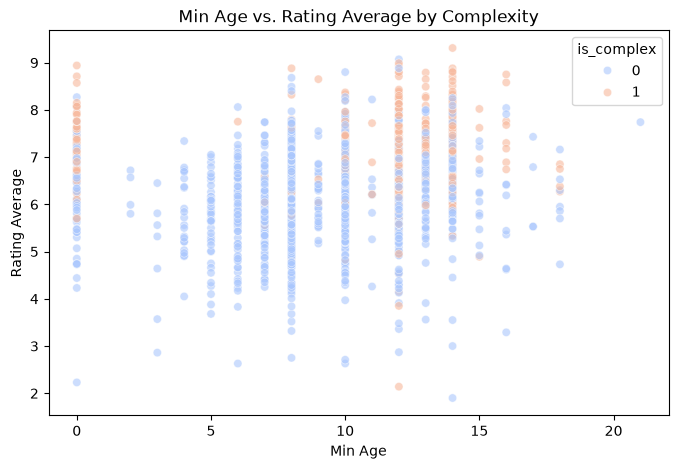

In [4]:
# Compute correlations with the target
corr = analysis_df.corr()['is_complex'].sort_values(ascending=False)
print("Correlation with is_complex:")
print(corr)

# Visualize a key pair of predictive variables (e.g., Min Age vs Play Time or Rating Average)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=analysis_df.sample(min(2000, len(analysis_df)), random_state=42), 
    x='Min Age', 
    y='Rating Average', 
    hue='is_complex', 
    alpha=0.6,
    palette='coolwarm'
)
plt.title("Min Age vs. Rating Average by Complexity")
plt.show()

In [5]:
X = analysis_df[candidate_features]
y = analysis_df['is_complex']

# Split into 80/20 train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

print("--- Logistic Regression Results ---")
print(classification_report(y_test, y_pred_lr))

# Model 2: Linear SVM
linear_svm = LinearSVC(dual='auto', max_iter=2000, random_state=42)
linear_svm.fit(X_train_scaled, y_train)
y_pred_svm = linear_svm.predict(X_test_scaled)

print("--- Linear SVM Results ---")
print(classification_report(y_test, y_pred_svm))

--- Logistic Regression Results ---
              precision    recall  f1-score   support

           0       0.86      0.95      0.90      2947
           1       0.82      0.59      0.68      1122

    accuracy                           0.85      4069
   macro avg       0.84      0.77      0.79      4069
weighted avg       0.85      0.85      0.84      4069

--- Linear SVM Results ---
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      2947
           1       0.85      0.55      0.67      1122

    accuracy                           0.85      4069
   macro avg       0.85      0.76      0.79      4069
weighted avg       0.85      0.85      0.84      4069



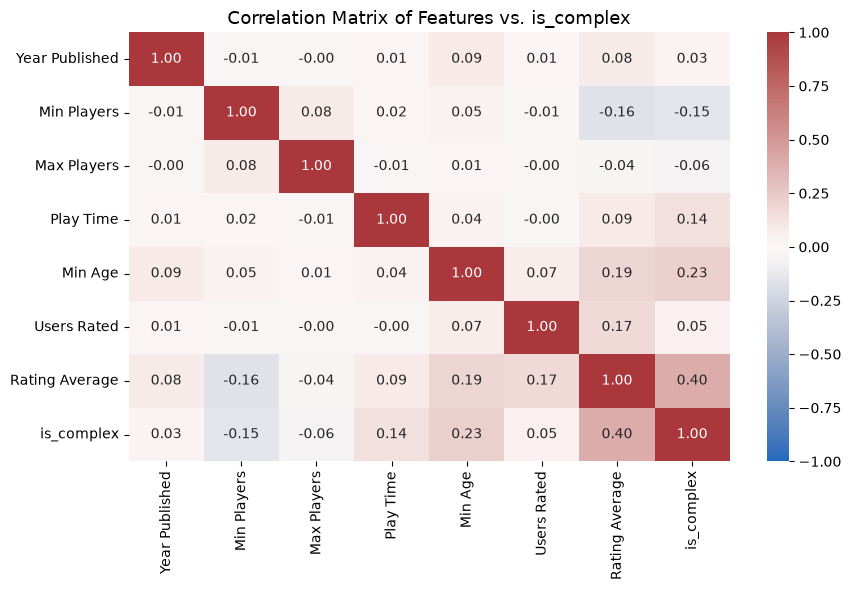

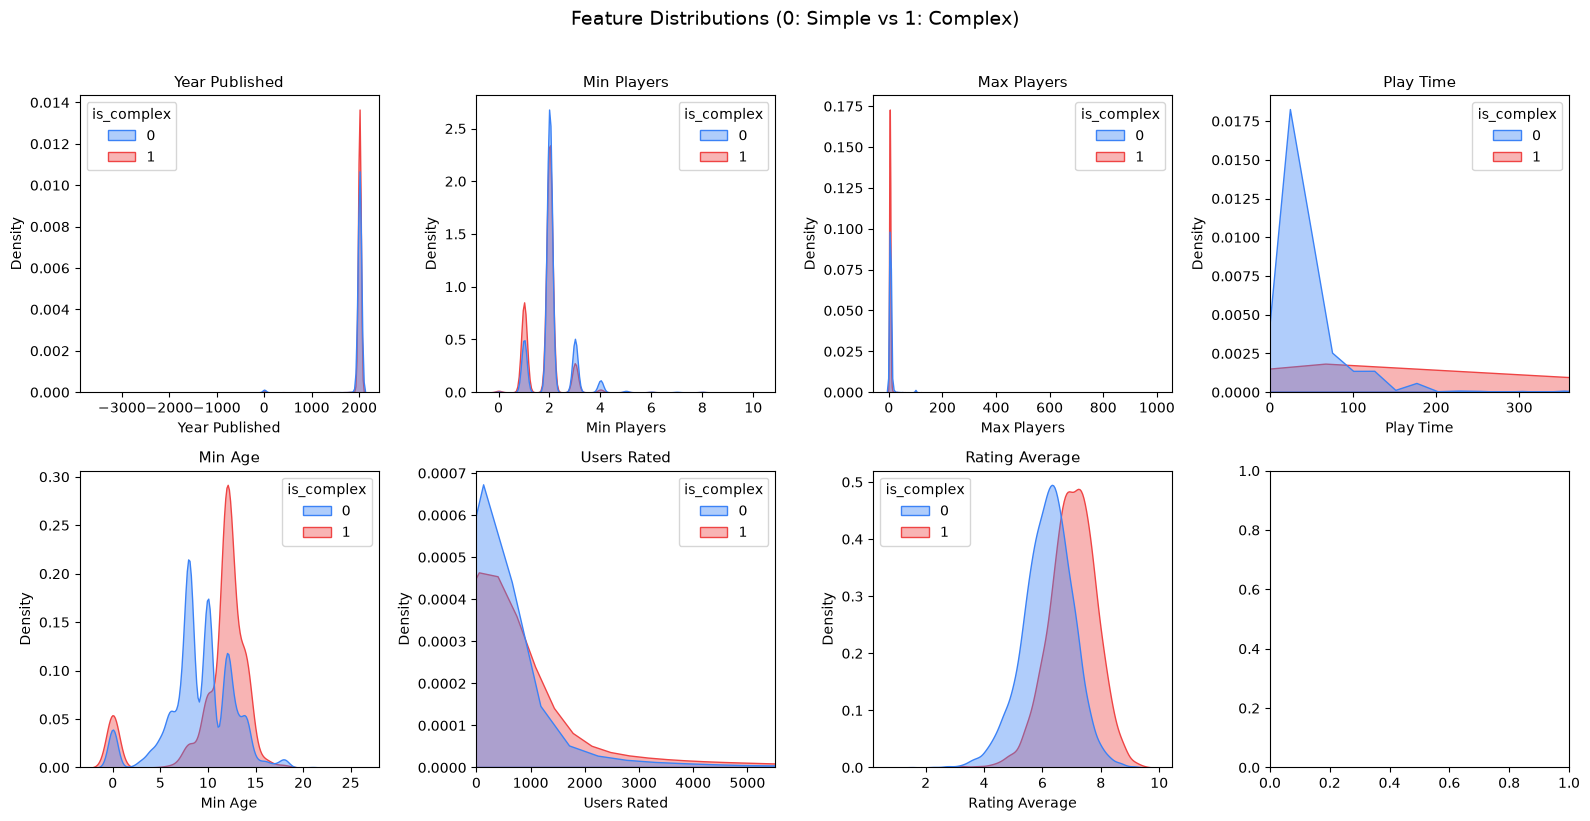

In [6]:
# 1. Correlation Heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(analysis_df.corr(), annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix of Features vs. is_complex", fontsize=13)
plt.tight_layout()
plt.show()

# 2. Feature Distribution by Complexity Class
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, col in enumerate(candidate_features):
    sns.kdeplot(
        data=analysis_df, 
        x=col, 
        hue='is_complex', 
        common_norm=False, 
        fill=True, 
        alpha=0.4, 
        palette=['#3b82f6', '#ef4444'], 
        ax=axes[idx]
    )
    # Clip extreme display tails for skewed features to keep plots readable
    if col in ['Play Time', 'Users Rated', 'Owned Users']:
        upper_limit = analysis_df[col].quantile(0.97)
        axes[idx].set_xlim(0, upper_limit)
    axes[idx].set_title(col, fontsize=11)

plt.suptitle("Feature Distributions (0: Simple vs 1: Complex)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

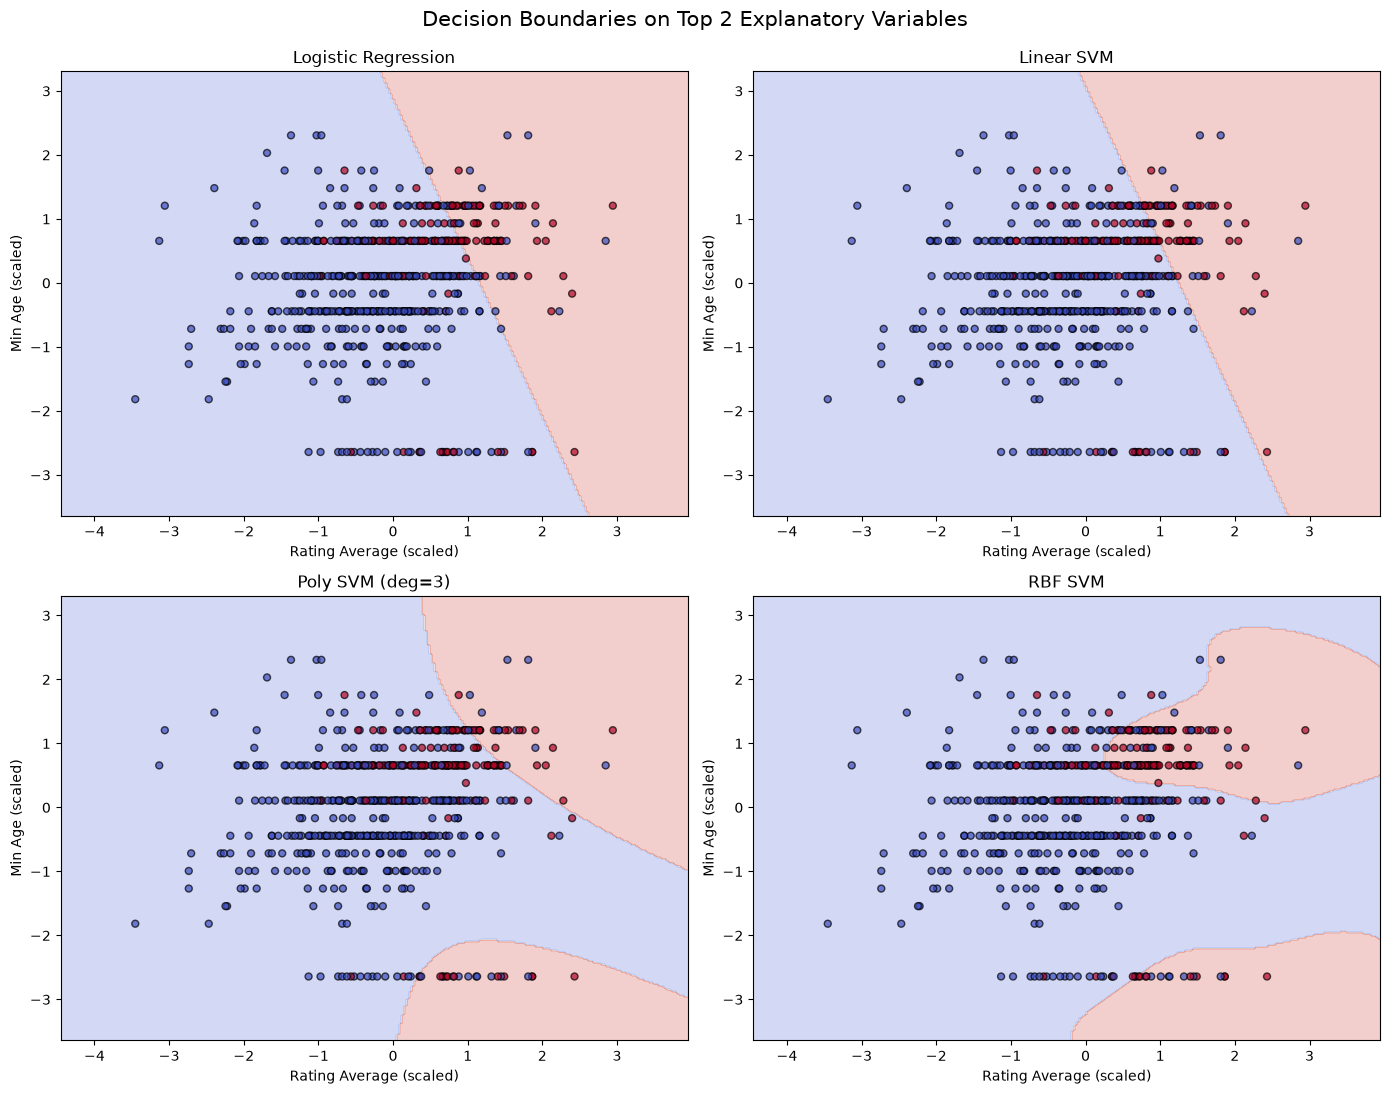

In [7]:
# Focus on the two most correlated features
features_2d = ['Rating Average', 'Min Age']
X_2d = analysis_df[features_2d]
y_2d = analysis_df['is_complex']

X_tr_2d, X_te_2d, y_tr_2d, y_te_2d = train_test_split(
    X_2d, y_2d, test_size=0.2, random_state=42, stratify=y_2d
)

scaler_2d = StandardScaler()
X_tr_2d_scaled = scaler_2d.fit_transform(X_tr_2d)
X_te_2d_scaled = scaler_2d.transform(X_te_2d)

# Subsample for smooth, fast boundary plotting
plot_idx = np.random.choice(len(X_te_2d_scaled), 600, replace=False)
X_vis = X_te_2d_scaled[plot_idx]
y_vis = y_te_2d.iloc[plot_idx].values

models_2d = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Linear SVM": LinearSVC(dual='auto', max_iter=3000, random_state=42),
    "Poly SVM (deg=3)": SVC(kernel='poly', degree=3, random_state=42),
    "RBF SVM": SVC(kernel='rbf', gamma='scale', random_state=42)
}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for idx, (title, model) in enumerate(models_2d.items()):
    model.fit(X_tr_2d_scaled, y_tr_2d)
    
    DecisionBoundaryDisplay.from_estimator(
        model, 
        X_vis, 
        response_method="predict",
        cmap="coolwarm", 
        alpha=0.25, 
        ax=axes[idx],
        grid_resolution=250
    )
    scatter = axes[idx].scatter(
        X_vis[:, 0], X_vis[:, 1], 
        c=y_vis, 
        cmap="coolwarm", 
        edgecolors='k', 
        s=25, 
        alpha=0.7
    )
    axes[idx].set_title(title, fontsize=12)
    axes[idx].set_xlabel(f"{features_2d[0]} (scaled)")
    axes[idx].set_ylabel(f"{features_2d[1]} (scaled)")

plt.suptitle("Decision Boundaries on Top 2 Explanatory Variables", fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

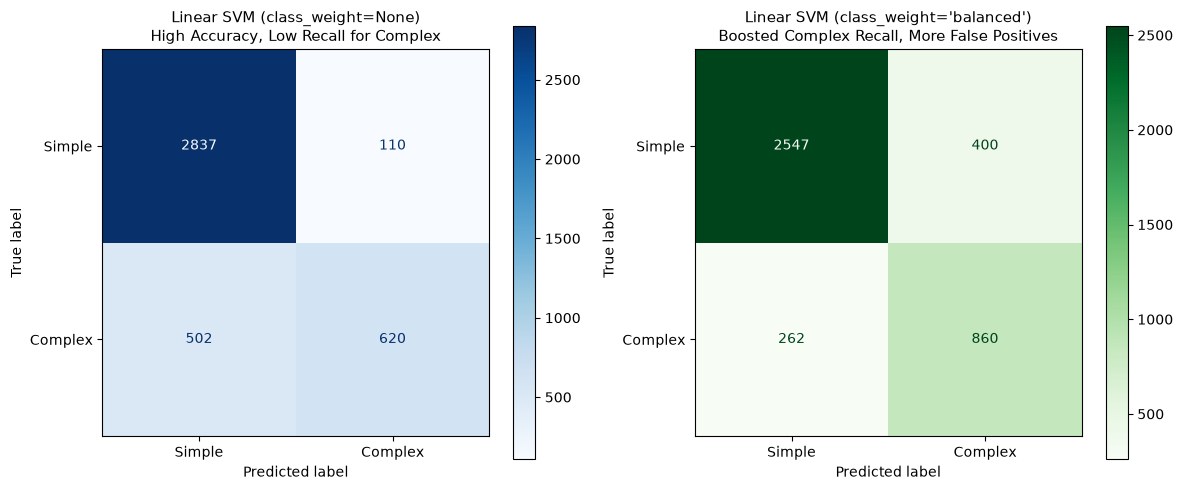

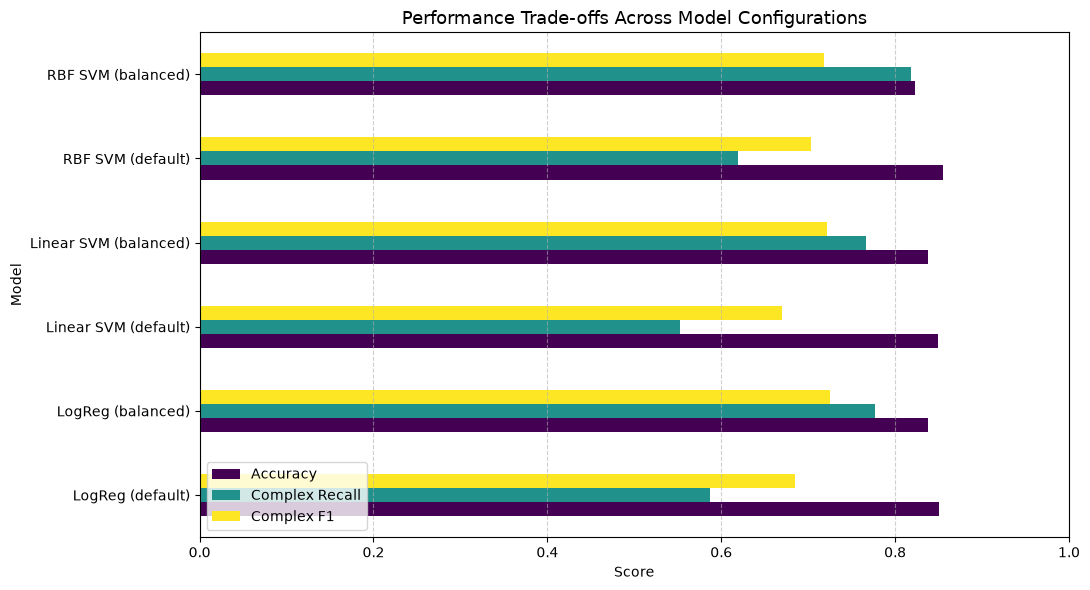

In [8]:
# Train default vs balanced Linear SVMs on the full feature set
svm_unweighted = LinearSVC(dual='auto', class_weight=None, max_iter=2000, random_state=42)
svm_balanced = LinearSVC(dual='auto', class_weight='balanced', max_iter=2000, random_state=42)

svm_unweighted.fit(X_train_scaled, y_train)
svm_balanced.fit(X_train_scaled, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    svm_unweighted, X_test_scaled, y_test, 
    display_labels=["Simple", "Complex"], 
    cmap="Blues", 
    ax=axes[0]
)
axes[0].set_title("Linear SVM (class_weight=None)\nHigh Accuracy, Low Recall for Complex", fontsize=11)

ConfusionMatrixDisplay.from_estimator(
    svm_balanced, X_test_scaled, y_test, 
    display_labels=["Simple", "Complex"], 
    cmap="Greens", 
    ax=axes[1]
)
axes[1].set_title("Linear SVM (class_weight='balanced')\nBoosted Complex Recall, More False Positives", fontsize=11)

plt.tight_layout()
plt.show()

# Metric summary chart across models
model_suite = {
    "LogReg (default)": LogisticRegression(random_state=42),
    "LogReg (balanced)": LogisticRegression(class_weight='balanced', random_state=42),
    "Linear SVM (default)": LinearSVC(dual='auto', max_iter=2000, random_state=42),
    "Linear SVM (balanced)": LinearSVC(dual='auto', class_weight='balanced', max_iter=2000, random_state=42),
    "RBF SVM (default)": SVC(kernel='rbf', random_state=42),
    "RBF SVM (balanced)": SVC(kernel='rbf', class_weight='balanced', random_state=42)
}

records = []
for name, clf in model_suite.items():
    clf.fit(X_train_scaled, y_train)
    preds = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    p, r, f, _ = precision_recall_fscore_support(y_test, preds, average=None)
    records.append({
        'Model': name,
        'Accuracy': acc,
        'Complex Precision': p[1],
        'Complex Recall': r[1],
        'Complex F1': f[1]
    })

perf_df = pd.DataFrame(records).set_index('Model')

perf_df[['Accuracy', 'Complex Recall', 'Complex F1']].plot(
    kind='barh', 
    figsize=(11, 6), 
    colormap='viridis'
)
plt.title("Performance Trade-offs Across Model Configurations", fontsize=13)
plt.xlabel("Score")
plt.xlim(0, 1.0)
plt.legend(loc='lower left')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [9]:
earthquake = pd.read_csv("data/earthquake_data_tsunami.csv")

In [10]:
display(earthquake.head())
display(earthquake.columns)

,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
0,7.0,8,7,768,117,0.509,17.0,14.000,-9.7963,159.596,2022,11,1
1,6.9,4,4,735,99,2.229,34.0,25.000,-4.9559,100.738,2022,11,0
2,7.0,3,3,755,147,3.125,18.0,579.000,-20.0508,-178.346,2022,11,1
3,7.3,5,5,833,149,1.865,21.0,37.000,-19.2918,-172.129,2022,11,1
4,6.6,0,2,670,131,4.998,27.0,624.464,-25.5948,178.278,2022,11,1


Index(['magnitude', 'cdi', 'mmi', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude', 'Year', 'Month', 'tsunami'],
      dtype='str')

<Axes: xlabel='longitude', ylabel='latitude'>

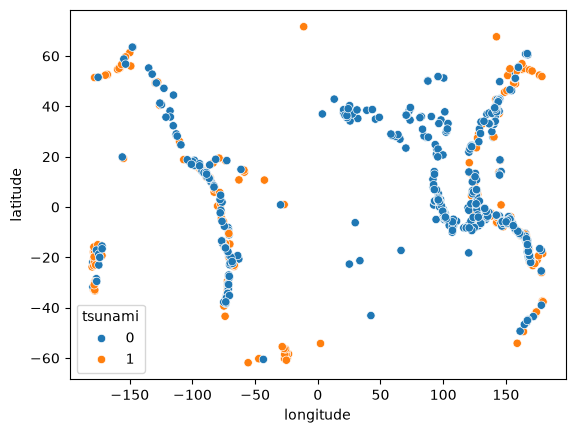

In [11]:
sns.scatterplot(data=earthquake, x="longitude", y="latitude", hue="tsunami")

<Axes: xlabel='Year', ylabel='Density'>

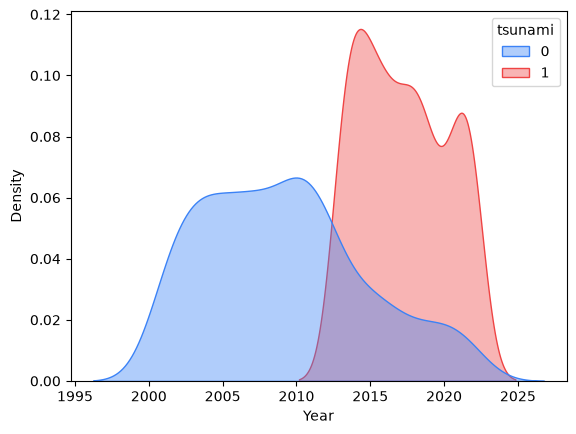

In [12]:
sns.kdeplot(
        data=earthquake, 
        x="Year", 
        hue='tsunami', 
        common_norm=False, 
        fill=True, 
        alpha=0.4, 
        palette=['#3b82f6', '#ef4444']
    )

In [13]:
X = earthquake[["longitude", "latitude", "magnitude", "Year"]]
y = earthquake['tsunami']

# Split into 80/20 train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

print("--- Logistic Regression Results ---")
print(classification_report(y_test, y_pred_lr))

# Model 2: Linear SVM
linear_svm = LinearSVC(dual='auto', max_iter=2000, random_state=42)
linear_svm.fit(X_train_scaled, y_train)
y_pred_svm = linear_svm.predict(X_test_scaled)

rbf_svm = SVC(kernel='rbf', gamma='scale', random_state=42, class_weight="balanced")
rbf_svm.fit(X_train_scaled, y_train)
y_pred_rbf_svm = rbf_svm.predict(X_test_scaled)

print("--- Linear SVM Results ---")
print(classification_report(y_test, y_pred_svm))

print("--- Radial SVM Results ---")
print(classification_report(y_test, y_pred_rbf_svm))


--- Logistic Regression Results ---
              precision    recall  f1-score   support

           0       0.81      0.86      0.83        96
           1       0.76      0.67      0.71        61

    accuracy                           0.79       157
   macro avg       0.78      0.77      0.77       157
weighted avg       0.79      0.79      0.79       157

--- Linear SVM Results ---
              precision    recall  f1-score   support

           0       0.82      0.85      0.84        96
           1       0.75      0.70      0.73        61

    accuracy                           0.80       157
   macro avg       0.79      0.78      0.78       157
weighted avg       0.79      0.80      0.79       157

--- Radial SVM Results ---
              precision    recall  f1-score   support

           0       0.97      0.77      0.86        96
           1       0.73      0.97      0.83        61

    accuracy                           0.85       157
   macro avg       0.85      0.87     

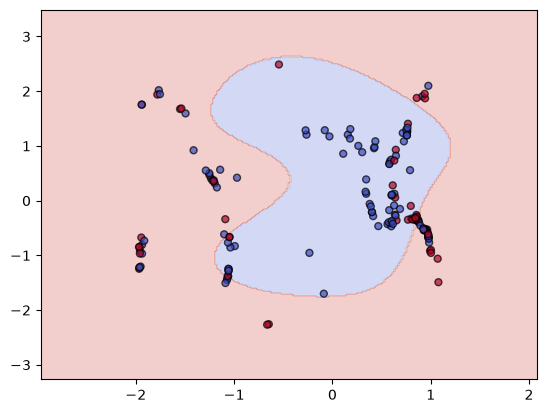

In [ ]:
X_te_2d = X_test[["longitude", "latitude"]]
y_te_2d = y_test

X_tr_2d = X_train[["longitude", "latitude"]]


scaler_2d = StandardScaler()
X_tr_2d_scaled = scaler_2d.fit_transform(X_tr_2d)
X_te_2d_scaled = scaler_2d.transform(X_te_2d)

X_vis = X_te_2d_scaled
y_vis = y_te_2d

rbf_svm_2d = SVC()
rbf_svm_2d = SVC(kernel='rbf', gamma='scale', random_state=42, class_weight="balanced")
rbf_svm_2d.fit(X_tr_2d_scaled, y_train)

DecisionBoundaryDisplay.from_estimator(
    rbf_svm_2d, 
    X_vis, 
    response_method="predict",
    cmap="coolwarm", 
    alpha=0.25, 
    grid_resolution=250
)
scatter = plt.scatter(
    X_vis[:, 0], X_vis[:, 1], 
    c=y_vis, 
    cmap="coolwarm", 
    edgecolors='k', 
    s=25, 
    alpha=0.7
)

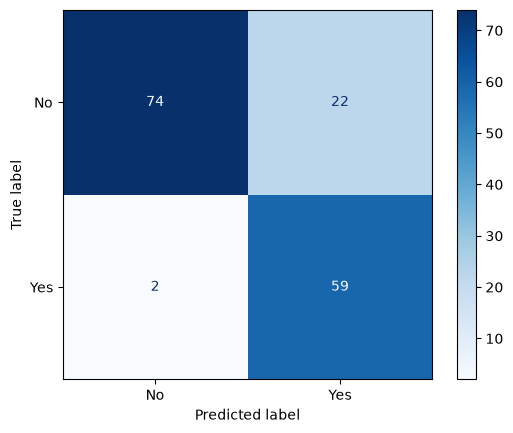

In [15]:
ConfusionMatrixDisplay.from_estimator(
    rbf_svm, X_test_scaled, y_test, 
    display_labels=["No", "Yes"], 
    cmap="Blues"
)